## -------------------------------------------------------------------------------------------------------------------

# PROYECTO DEL CEIEC - Network Traffic Classification, en colaboración con Foqum
# Descripción del notebook: entrenamiento de un modelo de clasificación transformer, con un semiflujo como dato de entrada, y como salida el tipo de tráfico (clase) a la que pertenece
# Becario responsable del proyecto: Carlos Arranz Luque
# Directora de la investigación: Ana María Maitín López
# Fecha: curso académico 2022-2023

## -------------------------------------------------------------------------------------------------------------------

## Importación de librerías y módulos

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import normalize
import configparser

## Módulos/scripts propios
from src import *

## Este código recarga los módulos/librerías antes de cada ejecución parcial del código, de tal forma
## que podemos cambiar una función en mitad de la ejecución y dichos cambios serán efectivos sin necesidad
## de recargar el kernel. Esto es útil cuando aún se está en fase de desarrollo y hay que verificar si las
## funciones tienen el comportamiento deseado
%load_ext autoreload
%autoreload 2

In [2]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

## -------------------------------------------------------------------------------------------------------------------

## Opciones de ejecución e hiperparámetros

In [3]:
## Leemos el archivo "config_entrenamiento.cfg" donde están las opciones de ejecución e hiperparámetros del entrenamiento
config = configparser.RawConfigParser()
config.read('config/config_entrenamiento_XFMR.cfg')

## Optenemos los diccionarios con los distintos parámetros de cada una de las categorías
opcionesEjecucion_dict = dict(config.items('OpcionesEjecucion'))
hiperparametros_dict = dict(config.items('Hiperparametros'))
rutasArchivos_dict = dict(config.items('RutasArchivos'))

In [4]:
### ----------------------------------------------------------------------------------------------
### ------------------------------ Opciones de ejecución -----------------------------------------
### ----------------------------------------------------------------------------------------------

# Si está a True, se cargan los pesos que se hayan guardado previamente para el archivo de semiflujos, que se 
# identifica con el "hashSemiflujos" (HS), y modelo en ejecucuión, que se identifica con el "hashModelo" (HM).
# (Junto con los pesos se cargan datos adicionales, como el tiempo que tardó el entrenamiento)
# Si no existen dichos pesos, la ejecución dará error. 
cargar_pesos = eval(opcionesEjecucion_dict['cargar_pesos'])

# Si está a True, se guardan los pesos del entrenamiento actual, sobreescribiendo anteriores pesos para este
# entrenamiento en concreto, ("hashSemiflujos" y "hashModelo"), de existir
guardar_pesos = eval(opcionesEjecucion_dict['guardar_pesos'])

# Si está a True, se guardan los resultados del entrenamiento actual (gráficas de entrenamiento, matriz de 
# confusión, métricas en el CSV y el archivo de configuración usado)
guardar_resultados = eval(opcionesEjecucion_dict['guardar_resultados'])

# Obtenemos el hash del archivo de semiflujos que vamos a utilizar para el entrenamiento
hashSemiflujos = opcionesEjecucion_dict['hashsemiflujos']


### ----------------------------------------------------------------------------------------------
### --------------------------------- Hiperparámetros --------------------------------------------
### ----------------------------------------------------------------------------------------------

# epochs --> Número de épocas a entrenar el modelo
# batch_size --> Tamaño del lote de entrenamiento
# learning_rate --> Tasa de aprendizaje a aplicar en el entrenamiento
# positional_encoding --> Si es 'True' aplica positional enconding al transformer
# num_heads --> Número de cabezas del encoder del transformer
# head_size --> Tamaño de cada cabeza
# mlp_units --> Número de neuronas de la capa 'dense' que hay a la salida del transformer
# ff_dim --> Número de filtros del Feed Forward del encoder
# mlp_dropout --> Tasa de dropout a aplicar en la capa MLP
# dropout --> Tasa de dropout a aplicar en el encoder del transformer
# num_capas_atencion --> Número de capas encoder del transformer
# num_folds --> Número de folds a usar en el KFold (se recomienda 5 ó 10)

epochs = int(hiperparametros_dict['epochs'])
batch_size = int(hiperparametros_dict['batch_size'])
learning_rate = float(hiperparametros_dict['learning_rate'])
positional_encoding = eval(hiperparametros_dict['positional_encoding'])
num_heads = int(hiperparametros_dict['num_heads'])
head_size = int(hiperparametros_dict['head_size'])
mlp_units = int(hiperparametros_dict['mlp_units'])
ff_dim = int(hiperparametros_dict['ff_dim'])
mlp_dropout = float(hiperparametros_dict['mlp_dropout'])
dropout = float(hiperparametros_dict['dropout'])
num_capas_atencion = int(hiperparametros_dict['num_capas_atencion'])
num_folds = int(hiperparametros_dict['num_folds'])
normalizar = eval(hiperparametros_dict['normalizar'])

### ----------------------------------------------------------------------------------------------
### ----------------------------------- Rutas archivos -------------------------------------------
### ----------------------------------------------------------------------------------------------

# En "pathRelativoPesos" tenemos la ruta relativa donde se guardan los pesos del modelo
pathRelativoPesos = rutasArchivos_dict["pathrelativopesos"]

# En "rutaSemiflujos" tenemos la ruta relativa donde se encuentran los archivos de semiflujos del preprocesamiento
rutaSemiflujos = rutasArchivos_dict["rutasemiflujos"]

# En "rutaResultados" tenemos la ruta relativa donde se guardan los resultados del modelo 
rutaResultados = rutasArchivos_dict["rutaresultados"]


## -------------------------------------------------------------------------------------------------------------------

## Mostramos los parámetros leídos del archivo de configuración 
### (Así nos cercioramos qué ha leído el programa y evitamos errores de configuración)

In [5]:
print("Parámetros leídos del archivo de configuración: \n")
print("Cargar pesos = "+str(cargar_pesos))
print("Guardar pesos = "+str(guardar_pesos))
print("Guardar resultados = "+str(guardar_resultados))
print("Hash semiflujos = "+str(hashSemiflujos))
print("Epochs = "+str(epochs))
print("Batch size = "+str(batch_size))
print("Learning rate = "+str(learning_rate))
print("Positional enconding = "+str(positional_encoding))
print("Num heads = "+str(num_heads))
print("Head size = "+str(head_size))
print("MLP units = "+str(mlp_units))
print("FF dim = "+str(ff_dim))
print("MLP dropout = "+str(mlp_dropout))
print("Dropout = "+str(dropout))
print("Num capas atencion = "+str(num_capas_atencion))
print("Num folds = "+str(num_folds))
print("Normalizar = "+str(normalizar))
print("Path relativos pesos = "+str(pathRelativoPesos))
print("Ruta semiflujos = "+str(rutaSemiflujos))
print("Ruta resultados = "+str(rutaResultados))

Parámetros leídos del archivo de configuración: 

Cargar pesos = False
Guardar pesos = True
Guardar resultados = True
Hash semiflujos = d86bd8c1f06c6599b5d3ce9b434345d8
Epochs = 5
Batch size = 1000
Learning rate = 0.0003
Positional enconding = False
Num heads = 8
Head size = 6
MLP units = 250
FF dim = 256
MLP dropout = 0.5
Dropout = 0.5
Num capas atencion = 4
Num folds = 5
Normalizar = True
Path relativos pesos = Objetos preprocesados/Pesos_TransformerSimple/
Ruta semiflujos = Objetos preprocesados/Semiflujos/
Ruta resultados = Resultados/Resultados_TransformerSimple/


## -------------------------------------------------------------------------------------------------------------------

## Obtenemos el hash del los hiperparámetros del modelo, será necesario para identificar y distinguir este modelo de otros

In [6]:
## Este hash identifica el modelo transformer de clasificación exacto que va a ser creado, ya que se forma
## a partir de todos sus hiperparámetros
hashModelo = md5hash(str(hiperparametros_dict))
hashModelo

'b2e386123543c676f843a5acb08df21b'

## A partir de ahora este entrenamiento está identificado con el siguiente hash de de modelo y de semiflujos, los cuales se utilizarán para el nombrado de archivos de salida o resultados del entrenamiento

In [7]:
print("HASH MODELO (HM) = "+hashModelo)
print("HASH SEMIFLUJOS (HS) = "+hashSemiflujos)

HASH MODELO (HM) = b2e386123543c676f843a5acb08df21b
HASH SEMIFLUJOS (HS) = d86bd8c1f06c6599b5d3ce9b434345d8


In [8]:
## Si vamos a guardar los resultados, creamos el directorio para las gráficas de entrenamiento si no está creado ya
if (guardar_resultados == True):
    crear_directorio_graficas(hashSemiflujos,hashModelo,rutaResultados)

Directorio ya existente!


## -------------------------------------------------------------------------------------------------------------------

## Cargar semiflujos y datos relacionados

In [9]:
## Cargamos todos los datos relacionados con el hash de semiflujos proporcionado en el archivo de configuración
## Esto datos son:
##     - El propio array con los semiflujos
##     - El array de etiquetas de los semiflujos
##     - El diccionario que indica las características del array de semiflujos

array_semiflujos, array_etiquetas, diccionario_semiflujos = cargar_semiflujos(hashSemiflujos,rutaSemiflujos)

In [10]:
## Vamos a imprimir la información de los semiflujos que acabamos de importar

total_semiflujos_procesados = 0

## Lista donde guardamos los tipos de comunicacion que tiene el array de semiflujos de este entrenamiento
## Chat, Email, FileTransfer, etc.  Es nesario para la función de obtención de métricas
categorias_semiflujos = []

for key in diccionario_semiflujos:
    if (key == "FileTransfer"):
        ## Pequeña modificación debido al nombre tan largo de la clase, para que no se solape en la
        ## matriz de confusión con otras clases
        categorias_semiflujos.append("File\nTransfer")  
    else:
        categorias_semiflujos.append(key)
    num_semiflujos = diccionario_semiflujos[key]
    porcentaje = round( (num_semiflujos/array_semiflujos.shape[0]*100) , 2)
    print("\nHemos obtenido una lista de "+str(num_semiflujos)+" semiflujos del tipo "+key+\
          ",\nlos cuales representan un "+str(porcentaje)+"% del total de semiflujos.")
    total_semiflujos_procesados+=num_semiflujos
    
print("\nEl total de semiflujos registrado en el diccionario de contenido son "+ str(total_semiflujos_procesados)+".")
print("\nLas dimensiones del array tridimensional de semiflujos son: "+str(array_semiflujos.shape)+".")
print("Esto significa que cada semiflujo esta compuesto por "+str(array_semiflujos.shape[1])+" paquetes,"\
      "\ny que cada paquete esta compuesto por "+str(array_semiflujos.shape[2])+" tokens.")
print("\nLas dimensiones del array de etiquetas son: "+str(array_etiquetas.shape)+".")
print("Esto significa que hay "+str(array_etiquetas.shape[1])+" clases de semiflujos. "\
    "(Esta en formato one hot encoding el etiquetado.)")


Hemos obtenido una lista de 1325 semiflujos del tipo Chat,
los cuales representan un 0.19% del total de semiflujos.

Hemos obtenido una lista de 168 semiflujos del tipo Email,
los cuales representan un 0.02% del total de semiflujos.

Hemos obtenido una lista de 266577 semiflujos del tipo FileTransfer,
los cuales representan un 38.65% del total de semiflujos.

Hemos obtenido una lista de 207405 semiflujos del tipo Streaming,
los cuales representan un 30.07% del total de semiflujos.

Hemos obtenido una lista de 214180 semiflujos del tipo VoIP,
los cuales representan un 31.06% del total de semiflujos.

El total de semiflujos registrado en el diccionario de contenido son 689655.

Las dimensiones del array tridimensional de semiflujos son: (689655, 20, 201).
Esto significa que cada semiflujo esta compuesto por 20 paquetes,
y que cada paquete esta compuesto por 201 tokens.

Las dimensiones del array de etiquetas son: (689655, 5).
Esto significa que hay 5 clases de semiflujos. (Esta en forma

## -------------------------------------------------------------------------------------------------------------------

## Normalización del array de semiflujos (o no)

In [11]:
if(normalizar == True):
    ## El numpy array de semiflujos esta con 'int' como tipo de dato, para que admita decimales cambiamos a 'float'
    array_semiflujos = array_semiflujos.astype('float32')

    ## La función "calcular_tiempo" imprime por pantalla el tiempo transcurrido y devuelve los minutos, esto último 
    ## será útil para almacenar el tiempo que tarda en entrenar el modelo
    start_time = time.time()

    ## Normalizamos semiflujo a semiflujo del array, y sustituimos cada uno por su versión normalizada
    for cont,semiflujo in enumerate(array_semiflujos):
        array_semiflujos[cont] = normalize(semiflujo,norm='max')

    calcular_tiempo(start_time)

    ## Si se quiere comprobar que se han normalizado correctamente los datos, basta con imprimir un paquete de un semiflujo
    ## array_semiflujos[9][0]  #(Primer paquete del décimo semiflujo)



--------------------------------------------------------------------------------------------------
Este módulo de código ha tardado 0 minutos y 28 segundos en ejecutarse
--------------------------------------------------------------------------------------------------


## -------------------------------------------------------------------------------------------------------------------

## A continuación, dividimos el dataset en train, validation y test

### Primero reservamos un 10% de los datos para test
#### Link al método de Scikit Learn usado (train_test_split): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [12]:
## Nos quedamos con un 10% para test, asegurándonos de que nos quedamos además con la misma proporción de clases 
## en el set de training que en el de test, ya que tenemos clases desbalanceadas. 
## (Tener la misma proporción de cada clase se consigue con la opción stratify de "train_test_split")

X_train_bruto, X_test, y_train_bruto, y_test = train_test_split(array_semiflujos, array_etiquetas,\
                                                                test_size=0.1, stratify=array_etiquetas,\
                                                                shuffle = True, random_state = 50)


## Vamos a verificar que hemos mantenido la misma proporción en ambos set de datos comparado con el original
imprimir_contenido_etiquetas_set(array_etiquetas, "COMPLETO_ORIGINAL")
imprimir_contenido_etiquetas_set(y_train_bruto, "TRAIN_BRUTO")
imprimir_contenido_etiquetas_set(y_test, "TEST")




Información del set COMPLETO_ORIGINAL:

Para la categoría 0 hay 1325 semiflujos de 689655, lo que supone un 0.19% del total.
Para la categoría 1 hay 168 semiflujos de 689655, lo que supone un 0.02% del total.
Para la categoría 2 hay 266577 semiflujos de 689655, lo que supone un 38.65% del total.
Para la categoría 3 hay 207405 semiflujos de 689655, lo que supone un 30.07% del total.
Para la categoría 4 hay 214180 semiflujos de 689655, lo que supone un 31.06% del total.
En total el set contiene 689655 semiflujos.


Información del set TRAIN_BRUTO:

Para la categoría 0 hay 1193 semiflujos de 620689, lo que supone un 0.19% del total.
Para la categoría 1 hay 151 semiflujos de 620689, lo que supone un 0.02% del total.
Para la categoría 2 hay 239919 semiflujos de 620689, lo que supone un 38.65% del total.
Para la categoría 3 hay 186664 semiflujos de 620689, lo que supone un 30.07% del total.
Para la categoría 4 hay 192762 semiflujos de 620689, lo que supone un 31.06% del total.
En total el 

### Con el set training bruto haremos  k-fold cross validation. 
#### Link al método de Scikit Learn usado (StratifiedKFold): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

In [13]:
## Definimos nuestro KFold estratificado (lo hacemos estratificado para que conserve los mismos porcentajes
## de cada clase en cada fold)
#skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=50)
skf = StratifiedKFold(n_splits=num_folds, shuffle=False)

## Transformamos "y_train_bruto" de one hot encoding a una única dimensión, es lo que acepta "StratifiedKFold",
## aunque para entrenar el modelo seguiremos usando one hot encoding, esta transformación es sólo momentánea
#y_train_bruto_transformado = np.argmax(y_train_bruto,axis=1)
array_etiquetas_transformado = np.argmax(array_etiquetas,axis=1)
## Ejemplo:
## y_train_bruto[0] = [1, 0, 0]   ## ONE HOT ENCODING    
## y_train_bruto_transformado[0] = 0   ## UNA ÚNICA DIMENSIÓN


## Lista donde guardaremos los índices de train y test indicados para cada SPLIT del KFOLD
lista_KFold = []

print("El KFold se ha generado con un número de folds igual a "+str(num_folds))



for num, (train, test) in enumerate(skf.split(array_semiflujos, array_etiquetas_transformado)): 
#for num, (train, test) in enumerate(skf.split(X_train_bruto, y_train_bruto_transformado)): 
    
    ## Introducimos a la lista los índices que hemos de usar en este SPLIT del KFOLD
    lista_KFold.append((train,test))
    
    ## Imprimimos la información de cada SPLIT del KFOLD, comprobando así que se han preservado los porcentajes
    ## de cada clase y que no ha habido errores
    print("\n-----------------------------------------------------------")
    print("-----------------------------------------------------------")
    print("INFORMACIÓN DEL SPLIT N°"+str(num))
    
    #training_folds = y_train_bruto[train]
    training_folds = array_etiquetas[train] 
    imprimir_contenido_etiquetas_set(training_folds, "TRAINING_FOLDS")
    
    #test_fold = y_train_bruto[test]  
    test_fold = array_etiquetas[test]
    imprimir_contenido_etiquetas_set(test_fold, "TEST_FOLD")
    print("-----------------------------------------------------------")
  

El KFold se ha generado con un número de folds igual a 5

-----------------------------------------------------------
-----------------------------------------------------------
INFORMACIÓN DEL SPLIT N°0


Información del set TRAINING_FOLDS:

Para la categoría 0 hay 1060 semiflujos de 551724, lo que supone un 0.19% del total.
Para la categoría 1 hay 134 semiflujos de 551724, lo que supone un 0.02% del total.
Para la categoría 2 hay 213262 semiflujos de 551724, lo que supone un 38.65% del total.
Para la categoría 3 hay 165924 semiflujos de 551724, lo que supone un 30.07% del total.
Para la categoría 4 hay 171344 semiflujos de 551724, lo que supone un 31.06% del total.
En total el set contiene 551724 semiflujos.


Información del set TEST_FOLD:

Para la categoría 0 hay 265 semiflujos de 137931, lo que supone un 0.19% del total.
Para la categoría 1 hay 34 semiflujos de 137931, lo que supone un 0.02% del total.
Para la categoría 2 hay 53315 semiflujos de 137931, lo que supone un 38.65% del

## -------------------------------------------------------------------------------------------------------------------

## Creación del modelo 

In [14]:
n_classes = y_train_bruto.shape[1]
input_shape = X_train_bruto.shape[1:]

## Construimos nuestro transformer clasificador
model = build_keras_transformer_model(input_shape, n_classes,head_size=head_size, num_heads=num_heads, PE=positional_encoding,\
                                      ff_dim=ff_dim, mlp_units=mlp_units,mlp_dropout=mlp_dropout, dropout=dropout,num_capas_atencion = num_capas_atencion)

## Lo compilamos eligiendo el tipo de loss, optimizador y métricas
model.compile(loss='categorical_crossentropy',optimizer=keras.optimizers.Adam(learning_rate=learning_rate),metrics=["accuracy"])

## Guardamos los pesos vírgenes para poder resetear el modelo en cada split del KFold, pero manteniendo
## los mismos pesos iniciales aleatorios, para que todos los splits partan en igualdad de condiciones
pesos_virgenes = model.get_weights()

## Imprimimos la arquitectura del modelo creado

In [15]:
model.summary()

Model: "categorical_PD_transformer"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 20, 201)]    0           []                               
                                                                                                  
 multi_head_attention (MultiHea  (None, 20, 201)     38937       ['input_1[0][0]',                
 dAttention)                                                      'input_1[0][0]']                
                                                                                                  
 dropout (Dropout)              (None, 20, 201)      0           ['multi_head_attention[0][0]']   
                                                                                                  
 tf.__operators__.add (TFOpLamb  (None, 20, 201)     0           ['dropou

 mbda)                                                            'tf.__operators__.add_6[0][0]'] 
                                                                                                  
 global_average_pooling1d (Glob  (None, 20)          0           ['tf.__operators__.add_7[0][0]'] 
 alAveragePooling1D)                                                                              
                                                                                                  
 dense (Dense)                  (None, 250)          5250        ['global_average_pooling1d[0][0]'
                                                                 ]                                
                                                                                                  
 dropout_8 (Dropout)            (None, 250)          0           ['dense[0][0]']                  
                                                                                                  
 dense_1 (

## -------------------------------------------------------------------------------------------------------------------

## Comprobamos si tenemos que cargar unos pesos previamente entrenados o si vamos a realizar un entrenamiento de cero

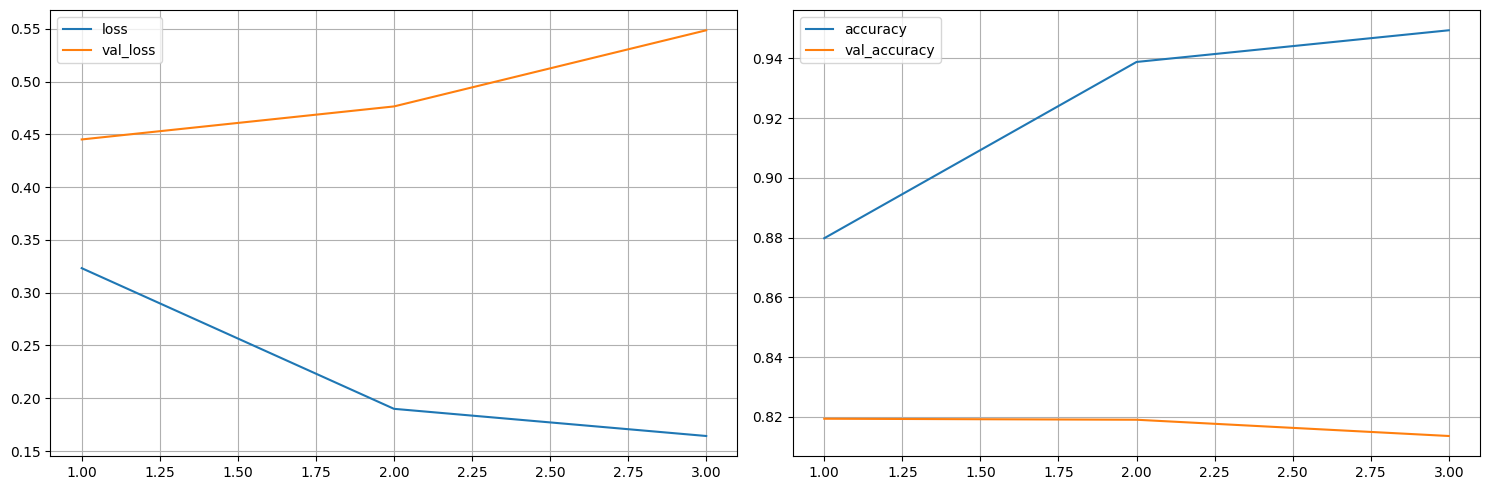

552/552 [==============================] - 37s 67ms/step - loss: 0.1643 - accuracy: 0.9494 - val_loss: 0.5485 - val_accuracy: 0.8136
Epoch 4/5
153/552 [=======>......................] - ETA: 26s - loss: 0.1580 - accuracy: 0.9503

KeyboardInterrupt: 

In [17]:
## Diccionario que contendrá los pesos, el tiempo de entrenamiento del modelo y las métricas de 
## loss/accuracy medias del KFold
dic_modelo = {}

if (cargar_pesos == True):
    ## Cargamos el diccionario del modelo y semiflujos de esta ejecución (si no existe error...)
    dic_modelo = obtener_pesos_modelo(hashSemiflujos, hashModelo, pathRelativoPesos, 'XFMR')
    ## Cargamos los pesos entrenados al modelo
    model.set_weights(dic_modelo['pesos'])
    ## Cargamos los resultados que se obtuvieron de training/validación y el tiempo que tardó el entrenamiento
    media_train_accuracy = dic_modelo['media_train_accuracy']
    media_train_loss = dic_modelo['media_train_loss']
    media_val_accuracy = dic_modelo['media_val_accuracy']
    media_val_loss = dic_modelo['media_val_loss']
    min_entrenamiento = dic_modelo['min_entrenamiento']

else:
    ## Vamos a entrenar el modelo
    start_time = time.time()
    
    media_train_accuracy,media_train_loss,media_val_accuracy,media_val_loss,min_entrenamiento = \
    entrenar_transformer_kfold(lista_KFold,array_semiflujos,array_etiquetas,dic_modelo,pesos_virgenes,\
                               model,input_shape,n_classes,head_size,num_heads,positional_encoding,\
                               ff_dim,mlp_units,mlp_dropout,dropout,num_capas_atencion,learning_rate,\
                               batch_size,epochs,rutaResultados,hashSemiflujos,hashModelo,guardar_resultados)
    
#     media_train_accuracy,media_train_loss,media_val_accuracy,media_val_loss,min_entrenamiento = \
#     entrenar_transformer_kfold(lista_KFold,X_train_bruto,y_train_bruto,dic_modelo,pesos_virgenes,\
#                                model,input_shape,n_classes,head_size,num_heads,positional_encoding,\
#                                ff_dim,mlp_units,mlp_dropout,dropout,num_capas_atencion,learning_rate,\
#                                batch_size,epochs,rutaResultados,hashSemiflujos,hashModelo,guardar_resultados)
    
    calcular_tiempo(start_time)

## -------------------------------------------------------------------------------------------------------------------

## Evaluamos el modelo con el set de test 

In [ ]:
## Calculamos el loss y accuracy sobre el set de test
loss_test, accuracy_test = model.evaluate(X_test, y_test, batch_size=batch_size, verbose=1)

## Obtenemos las predicciones para poder obtener métricas
y_pred = model.predict(X_test,batch_size=batch_size)


## -------------------------------------------------------------------------------------------------------------------

## Métricas finales del modelo

In [ ]:
## Obtenemos e imprimimos las métricas
dic_metricas = obtener_metricas_modelo(y_test,y_pred,accuracy_test,loss_test,media_train_accuracy,media_train_loss\
                                       ,media_val_accuracy,media_val_loss,hashSemiflujos, hashModelo,\
                                       rutaResultados, guardar_resultados,categorias_semiflujos)


## Obtener características de uso del PC

In [ ]:
if (cargar_pesos == False):
    CPU,RAM,picoRAM,nombre_GPU,VRAM,picoVRAM = obtener_especificaciones_pc()
else: 
    ## Obtenemos las características del entrenamiento que ya se hizo
    CPU = dic_modelo['CPU']
    RAM = dic_modelo['RAM']
    picoRAM = dic_modelo['picoRAM']
    nombre_GPU = dic_modelo['nombre_GPU']
    VRAM = dic_modelo['VRAM']
    picoVRAM = dic_modelo['picoVRAM']
    

## Guardar resultados (o no)

In [ ]:
if(guardar_resultados == True):
    ## Añadimos al diccionario de métricas los hiperparámetros utilizados, así como otros datos de interés
    dic_metricas["epochs"] = epochs
    dic_metricas["batch_size"] = batch_size
    dic_metricas["learning_rate"] = learning_rate
    dic_metricas["positional_encoding"] = positional_encoding
    dic_metricas["num_heads"] = num_heads
    dic_metricas["head_size"] = head_size
    dic_metricas["mlp_units"] = mlp_units
    dic_metricas["ff_dim"] = ff_dim
    dic_metricas["mlp_dropout"] = mlp_dropout
    dic_metricas["dropout"] = dropout
    dic_metricas["num_capas_atencion"] = num_capas_atencion
    dic_metricas["num_folds"] = num_folds
    dic_metricas["normalizacion"] = normalizar
    dic_metricas["min_entrenamiento"] = min_entrenamiento 
    dic_metricas["hashSemiflujos"] = hashSemiflujos
    dic_metricas["hashModelo"] = hashModelo
    dic_metricas["timestamp"] = get_timestamp()
    dic_metricas["CPU"] = CPU
    dic_metricas["RAM"] = RAM
    dic_metricas["pico_uso_RAM"] = picoRAM
    dic_metricas["GPU"] = nombre_GPU
    dic_metricas["VRAM"] = VRAM
    dic_metricas["pico_uso_VRAM"] = picoVRAM
    ## Guardamos el diccionario de métricas en el CSV de métricas y resultados
    guardar_resultados_modelo(dic_metricas, rutaResultados,hashModelo,cargar_pesos)

## -------------------------------------------------------------------------------------------------------------------

## Último paso, guardar (o no) los pesos del modelo

In [ ]:
## Si la opción está habilitada, se guarda el diccionario con los pesos y tiempo de ejecución del modelo

if (guardar_pesos == True):
    dic_modelo['pesos'] = model.get_weights()
    dic_modelo['media_train_accuracy'] = media_train_accuracy
    dic_modelo['media_train_loss'] = media_train_loss
    dic_modelo['media_val_accuracy'] = media_val_accuracy
    dic_modelo['media_val_loss'] = media_val_loss
    dic_modelo['CPU'] = CPU
    dic_modelo['RAM'] = RAM
    dic_modelo['picoRAM'] = picoRAM
    dic_modelo['nombre_GPU'] = nombre_GPU
    dic_modelo['VRAM'] = VRAM
    dic_modelo['picoVRAM'] = picoVRAM
    guardar_pesos_modelo(hashSemiflujos,hashModelo, dic_modelo, pathRelativoPesos, 'XFMR')
    print("\nSe han guardado los pesos")
else:
    print("\nNO se han guardado los pesos")


## ------------------------------------- 🎉 FIN DEL NOTEBOOK 🎉 -------------------------------------